In [1]:
from pathlib import Path

image_dir = Path(r"C:\Deep learning CampusX\Data\UTKFace")

image_paths = sorted(image_dir.glob("*.jpg"))

print("Number of images:", len(image_paths))
print("\nFirst 5 filenames:")

for path in image_paths[:5]:
    print(path.name)

Number of images: 23708

First 5 filenames:
100_0_0_20170112213500903.jpg.chip.jpg
100_0_0_20170112215240346.jpg.chip.jpg
100_1_0_20170110183726390.jpg.chip.jpg
100_1_0_20170112213001988.jpg.chip.jpg
100_1_0_20170112213303693.jpg.chip.jpg


In [2]:
import pandas as pd

records = []
skipped = []

for path in image_paths:
    parts = path.name.split("_")

    try:
        age = int(parts[0])
        gender = int(parts[1])

        if not (0 <= age <= 116 and gender in (0, 1)):
            raise ValueError("Invalid label")

        records.append({
            "image_path": str(path),
            "age": age,
            "gender": gender,
        })

    except (ValueError, IndexError):
        skipped.append(path.name)

face_df = pd.DataFrame(records)

display(face_df.head())

print("Valid images:", len(face_df))
print("Skipped filenames:", len(skipped))
print("\nGender-label counts:")
print(face_df["gender"].value_counts())

,image_path,age,gender
0,C:\Deep learning CampusX\Data\UTKFace\100_0_0_...,100,0
1,C:\Deep learning CampusX\Data\UTKFace\100_0_0_...,100,0
2,C:\Deep learning CampusX\Data\UTKFace\100_1_0_...,100,1
3,C:\Deep learning CampusX\Data\UTKFace\100_1_0_...,100,1
4,C:\Deep learning CampusX\Data\UTKFace\100_1_0_...,100,1


Valid images: 23708
Skipped filenames: 0

Gender-label counts:
gender
0    12391
1    11317
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    face_df,
    test_size=0.2,
    random_state=42,
    stratify=face_df["gender"],
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

Training images: 18966
Validation images: 4742


In [4]:
import tensorflow as tf

IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32

def load_image(image_path, labels):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    image = image / 255.0

    return image, labels


def make_dataset(frame, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((
        frame["image_path"].to_numpy(),
        {
            "age": frame["age"].to_numpy(
                dtype="float32"
            ).reshape(-1, 1),

            "gender": frame["gender"].to_numpy(
                dtype="float32"
            ).reshape(-1, 1),
        },
    ))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(frame),
            seed=42,
        )

    return (
        dataset
        .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
        .batch(BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
images, labels = next(iter(train_ds))

print("Images:", images.shape)
print("Age targets:", labels["age"].shape)
print("Gender targets:", labels["gender"].shape)

Images: (32, 128, 128, 3)
Age targets: (32, 1)
Gender targets: (32, 1)


In [23]:
# Functional model with one input and two output

from tensorflow import keras
from tensorflow.keras import layers

keras.backend.clear_session()

image_input = keras.Input(shape = (128,128,3), name = 'image_input')

x = layers.Conv2D(16 , kernel_size = 3, padding = 'same' , activation = 'relu')(image_input)
x = layers.MaxPooling2D(pool_size = 2)(x)
x = layers.Conv2D(32, kernel_size = 3 ,padding = 'same' , activation = 'relu')(x)
x = layers.MaxPooling2D(pool_size = 2)(x)
x = layers.Conv2D(64 , kernel_size = 3, padding = 'same' , activation = 'relu')(x)
x = layers.MaxPooling2D(pool_size = 2)(x)
x = layers.GlobalAveragePooling2D()(x)

shared_features = layers.Dense(64 , activation = 'relu')(x)
print(shared_features.shape)


(None, 64)


In [24]:
age_hidden = layers.Dense(32, activation = 'relu')(shared_features)
age_output = layers.Dense(1, activation = 'relu' , name = 'age')(age_hidden)


gender_hidden = layers.Dense(32 ,activation = 'relu')(shared_features)
gender_output = layers.Dense(1, activation = 'sigmoid', name = 'gender')(gender_hidden)

model = keras.Model(inputs = image_input , outputs = {'age' : age_output , 'gender' : gender_output}, name = 'utkface_multitask')
model.summary()

Model: "utkface_multitask"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        448 │ image_input[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ conv2d_2[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ max_pooling2d_2[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      4,160 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      2,080 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │      2,080 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ age (Dense)         │ (None, 1)         │         33 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gender (Dense)      │ (None, 1)         │         33 │ dense_2[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 31,970 (124.88 KB)

 Trainable params: 31,970 (124.88 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
Path("Models").mkdir(exist_ok=True)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),

    loss={
        "age": "mse",
        "gender": "binary_crossentropy",
    },

    loss_weights={
        "age": 0.01,
        "gender": 1.0,
    },

    metrics={
        "age": [keras.metrics.MeanAbsoluteError(name="mae")],
        "gender": [keras.metrics.BinaryAccuracy(name="accuracy")],
    },
)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1,
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1,
    ),

    keras.callbacks.ModelCheckpoint(
        filepath="Models/utkface_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),
]

In [26]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks,
)

Epoch 1/30
593/593 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - age_loss: 451.3456 - age_mae: 16.3079 - gender_accuracy: 0.5027 - gender_loss: 0.7137 - loss: 5.2278
Epoch 1: val_loss improved from None to 4.62137, saving model to Models/utkface_best.keras

Epoch 1: finished saving model to Models/utkface_best.keras
593/593 ━━━━━━━━━━━━━━━━━━━━ 75s 120ms/step - age_loss: 451.3456 - age_mae: 16.3079 - gender_accuracy: 0.5027 - gender_loss: 0.7137 - loss: 5.2278 - val_age_loss: 391.8361 - val_age_mae: 15.9153 - val_gender_accuracy: 0.4774 - val_gender_loss: 0.6937 - val_loss: 4.6214 - learning_rate: 0.0010
Epoch 2/30
592/593 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - age_loss: 381.1990 - age_mae: 15.0457 - gender_accuracy: 0.5681 - gender_loss: 0.6817 - loss: 4.4937
Epoch 2: val_loss improved from 4.62137 to 4.40646, saving model to Models/utkface_best.keras

Epoch 2: finished saving model to Models/utkface_best.keras
593/593 ━━━━━━━━━━━━━━━━━━━━ 46s 77ms/step - age_loss: 381.0180 - age_mae: 15.0431 - g

In [27]:
results = model.evaluate(
    val_ds,
    return_dict=True,
    verbose=1,
)

for name, value in results.items():
    print(f"{name}: {value:.4f}")

149/149 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - age_loss: 137.2948 - age_mae: 8.7783 - gender_accuracy: 0.7440 - gender_loss: 0.5139 - loss: 1.8878
age_loss: 137.2948
age_mae: 8.7783
gender_accuracy: 0.7440
gender_loss: 0.5139
loss: 1.8878


In [28]:
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    classification_report,
    confusion_matrix,
)

predictions = model.predict(val_ds, verbose=1)

predicted_age = predictions["age"].reshape(-1)
gender_probability = predictions["gender"].reshape(-1)
predicted_gender = (gender_probability >= 0.5).astype(int)

actual_age = val_df["age"].to_numpy()
actual_gender = val_df["gender"].to_numpy()

print(f"Age MAE:  {mean_absolute_error(actual_age, predicted_age):.2f} years")
print(f"Age RMSE: {np.sqrt(mean_squared_error(actual_age, predicted_age)):.2f} years")

print("\nGender classification report:")
print(classification_report(
    actual_gender,
    predicted_gender,
    labels=[0, 1],
    target_names=["Male (dataset label)", "Female (dataset label)"],
    zero_division=0,
))

print("Confusion matrix — rows: actual, columns: predicted")
print(confusion_matrix(actual_gender, predicted_gender, labels=[0, 1]))

149/149 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step
Age MAE:  8.78 years
Age RMSE: 11.72 years

Gender classification report:
                        precision    recall  f1-score   support

  Male (dataset label)       0.75      0.77      0.76      2478
Female (dataset label)       0.74      0.72      0.73      2264

              accuracy                           0.74      4742
             macro avg       0.74      0.74      0.74      4742
          weighted avg       0.74      0.74      0.74      4742

Confusion matrix — rows: actual, columns: predicted
[[1907  571]
 [ 643 1621]]


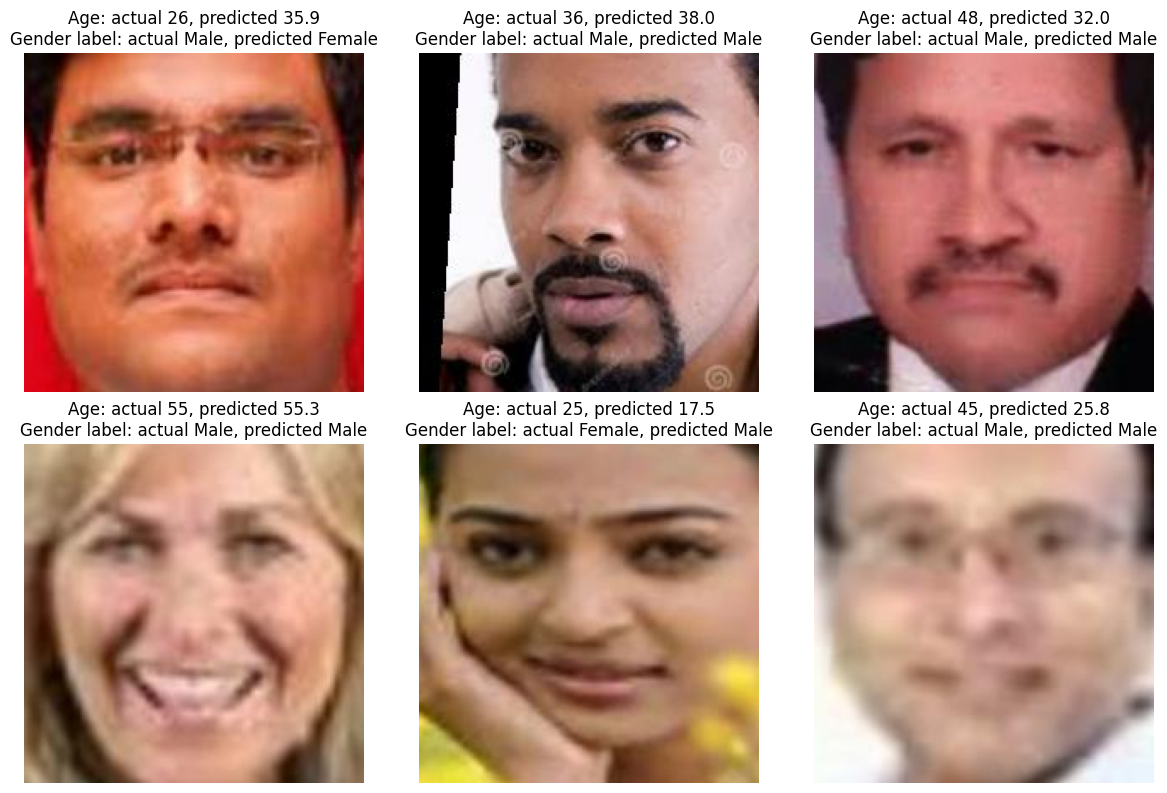

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
gender_names = {0: "Male", 1: "Female"}

for i, ax in enumerate(axes.flat):
    row = val_df.iloc[i]
    
    with Image.open(row["image_path"]) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(
        f"Age: actual {int(actual_age[i])}, predicted {predicted_age[i]:.1f}\n"
        f"Gender label: actual {gender_names[actual_gender[i]]}, "
        f"predicted {gender_names[predicted_gender[i]]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()